# Die-yield prediction: Model A and Model B

We deliver the **two models required by the problem** and compare them on the same eligible dies.

| Required model | Inputs | Our implementation | Outputs |
|---|---|---|---|
| **Model A - Die-level + spatial** | Parametric measurements, die positions, and pre-test status | Shared parametric signal and spatial features, followed by LightGBM | Failure probability, prediction, measurement and spatial explanations |
| **Model B - Die + block-level** | The same source inputs as Model A, plus block readings | Shared signal and spatial context, plus a noise-normalized block scan and regularized evidence fusion | Failure probability, prediction, measurement/spatial explanations and candidate abnormal block regions |

Model A never uses block-derived features and can predict without a block-readings column. Model B uses the same original die measurements and spatial context, with additional block information. Their final classifiers differ because we retained the configurations supported by training validation. Our A-to-B comparison measures the complete pipeline change; it is not a causal estimate of block information alone.

Our earlier development checks supported these two implementations. **This final notebook trains and evaluates only Model A and Model B.** It includes preprocessing, wafer-level validation, threshold selection, results, visualizations, explanations, and a separate submission for each model. No external Python script is required.

### Run in Google Colab
1. Place `train.csv`, `test.csv`, and `validation.csv` in a Google Drive folder.
2. Select a CPU runtime, edit `DATA_DIR` below, and run all cells in order.
3. Collect `model_A.joblib`, `model_B.joblib`, `submission_A.csv`, `submission_B.csv`, and our comparison/explanation files from the output folder.

We predict new failures among pre-test passing dies. We evaluate only `old_label == 0`, and retain old failures as failures in submissions. Our saved execution is local; we do not claim that it was executed remotely in Colab.

In [ ]:
# Install before importing numerical libraries. Exact versions record our tested environment.
import sys, subprocess, importlib.metadata as metadata
PINS = {'numpy':'2.5.3', 'pandas':'3.0.5', 'scipy':'1.18.1',
        'scikit-learn':'1.9.0', 'lightgbm':'4.7.0',
        'joblib':'1.6.0', 'matplotlib':'3.11.2'}
needed = []
for package, version in PINS.items():
    try: installed = metadata.version(package)
    except metadata.PackageNotFoundError: installed = None
    if installed != version: needed.append(f'{package}=={version}')
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *needed])
print('Dependencies ready. Python:', sys.version.split()[0])

Dependencies ready. Python: 3.13.0


In [ ]:
from pathlib import Path
import os, json, time, hashlib, gc, platform
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.ndimage import uniform_filter1d, gaussian_filter1d
from scipy.special import expit, logit, logsumexp
from scipy.stats import norm
from sklearn.model_selection import GroupKFold
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, brier_score_loss, log_loss, auc)
from lightgbm import LGBMClassifier

IN_COLAB = 'google.colab' in sys.modules or Path('/content').exists()
# EDIT this path to our data folder in Colab.
DATA_DIR = (Path('/content/drive/MyDrive/die_yield/input') if IN_COLAB else
            Path.cwd() / 'Hackathon Problem - Die Yield Prediction' / 'input')
OUTPUT_DIR = Path('/content/die_yield_outputs') if IN_COLAB else Path.cwd() / 'die_yield_outputs'
if IN_COLAB and str(DATA_DIR).startswith('/content/drive') and not DATA_DIR.exists():
    from google.colab import drive
    drive.mount('/content/drive')
assert DATA_DIR.exists(), f'Please set DATA_DIR to our input directory: {DATA_DIR}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = OUTPUT_DIR / 'cache'; CACHE_DIR.mkdir(exist_ok=True)
ROOT = V2 = CACHE_DIR  # Internal cache aliases; no external script dependencies.
DATA = DATA_DIR
SEED, N_FOLDS, N_JOBS = 42, 4, 4
DEFAULT_SETTING = 'precision_80'  # Fixed before we inspect final-test results.
REBUILD_FOLD_CACHE = False
PARAM = [c for c in pd.read_csv(DATA/'train.csv', nrows=0).columns if c.startswith('feature_')]
assert PARAM, 'No parametric feature columns found.'
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
versions = {p: metadata.version(p) for p in PINS}
(OUTPUT_DIR/'environment.json').write_text(json.dumps({'python':platform.python_version(), **versions}, indent=2))
display(pd.Series(versions, name='version').to_frame())
print('Data:', DATA_DIR, '\nOutputs:', OUTPUT_DIR)

,version
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.0
lightgbm,4.7.0
joblib,1.6.0
matplotlib,3.11.2


Data: C:\Users\adila\OneDrive\Desktop\sandisk2\Hackathon Problem - Die Yield Prediction\input 
Outputs: C:\Users\adila\OneDrive\Desktop\sandisk2\die_yield_outputs


## 1. Our preprocessing and evaluation contract

We stream the CSVs in chunks and compress each block array into interpretable summaries. We retain all parametric measurements as float32 to control memory. Feature caches record input size and modification time; we can remove `cache/` to force a cold run.

We check unique die coordinates, valid binary labels, finite measurements, and the rule that an old failure remains failed. We do not use wafer identifiers as predictors. Randomly splitting individual dies would put the same wafer into training and validation, so all our supervised validation splits are by wafer.

In [ ]:
def load(path):
    cache = ROOT / (path.stem + '_features.pkl')
    signature = [path.stat().st_size, path.stat().st_mtime_ns]
    if cache.exists():
        saved = joblib.load(cache)
        if saved['signature'] == signature:
            return saved['frame']
    parts = []
    for i, df in enumerate(pd.read_csv(path, chunksize=2000)):
        b = np.stack([np.fromstring(s, sep=' ', dtype=np.float32) for s in df.pop('block_readings')])
        df = df.copy()  # Consolidate mixed CSV blocks before adding summaries.
        df['block_mean'] = b.mean(1)
        df['block_std'] = b.std(1)
        for q in [0.01, 0.1, 0.5, 0.9, 0.99]:
            df[f'block_q{q}'] = np.quantile(b, q, axis=1)
        for w in [25, 100, 200, 400]:
            sm = uniform_filter1d(b, w, axis=1, mode='wrap')
            df[f'block_max_window_{w}'] = sm.max(1)
            df[f'block_window_std_{w}'] = sm.std(1)
        df = df.astype({c:np.float32 for c in PARAM}).copy()
        parts.append(df)
        if i % 10 == 0:
            print(f'{path.name}: {(i+1)*2000:,} rows parsed', flush=True)
    df = pd.concat(parts, ignore_index=True)
    joblib.dump({'signature': signature, 'frame': df}, cache, compress=0)
    return df

In [ ]:
started = time.perf_counter()
train = load(DATA/'train.csv').reset_index(drop=True)
KEYS = ['wafer_id','die_row','die_col']
def validate_frame(df, labeled=True):
    assert not df.duplicated(KEYS).any(), 'Duplicate die coordinates.'
    assert df.old_label.isin([0,1]).all(), 'Invalid pre-test labels.'
    assert np.isfinite(df[PARAM].to_numpy()).all(), 'Missing/nonfinite measurements need investigation.'
    if labeled:
        assert df.label.isin([0,1]).all()
        assert df.loc[df.old_label==1,'label'].eq(1).all()
validate_frame(train)
eligible = train.old_label.to_numpy()==0
audit = pd.DataFrame([{'split':'training','wafers':train.wafer_id.nunique(),
    'all_dies':len(train),'eligible_dies':int(eligible.sum()),
    'new_failures':int(train.loc[eligible,'label'].sum()),
    'eligible_failure_rate':train.loc[eligible,'label'].mean()}])
display(audit)
assert train.wafer_id.nunique() >= 2*N_FOLDS

,split,wafers,all_dies,eligible_dies,new_failures,eligible_failure_rate
0,training,160,173099,154037,6519,0.042321


## 2. Our spatial and parametric signal model

Our approach estimates a common failure direction across the measurements. Strong training failures help us estimate this direction with less noise. Within each wafer we robustly regress out row, column, radial, and pre-test-neighborhood drift, excluding extreme residuals while fitting the background. This uses measurements and **pre-test** labels only at prediction time.

We fit a two-component Gaussian mixture to the training failure scores to represent strong and marginal failures. A likelihood ratio combines this distribution with the passing-score distribution. We then estimate wafer-level failure prevalence from the unlabeled score evidence, with shrinkage toward the training prevalence. This allows higher-risk wafers to have higher prior risk without using their post-test outcomes.

We infer map extent from the supplied die coordinates and use 3x3, 5x5, and 9x9 old-failure densities. The complete wafer must be available for these contextual features. This distributional model is a useful hypothesis for our supplied synthetic data; it needs validation on production wafers.

In [ ]:
def geometry(df):
    from scipy.ndimage import uniform_filter
    out=pd.DataFrame(index=np.arange(len(df)))
    for _,g in df.groupby('wafer_id',sort=False):
        ix=g.index.to_numpy()
        r,c=g.die_row.to_numpy(),g.die_col.to_numpy()
        shape=(r.max()+1,c.max()+1)
        valid=np.zeros(shape); old=np.zeros(shape)
        valid[r,c]=1;old[r,c]=g.old_label
        nr=(r-shape[0]/2)/(shape[0]/2)
        nc=(c-shape[1]/2)/(shape[1]/2)
        out.loc[ix,'row']=nr;out.loc[ix,'col']=nc
        out.loc[ix,'radial']=np.sqrt((r-shape[0]/2)**2+(c-shape[1]/2)**2)/np.sqrt((shape[0]/2)**2+(shape[1]/2)**2)
        for w in [3,5,9]:
            a=uniform_filter(old,size=w,mode='constant')
            b=uniform_filter(valid,size=w,mode='constant')
            out.loc[ix,f'density_{w}']=a[r,c]/np.maximum(b[r,c],1e-9)
        out.loc[ix,'old_rate']=g.old_label.mean()
        out.loc[ix,'wafer_size']=len(g)
    return out

class Signal:
    def fit(self,df):
        x=df[PARAM].to_numpy(float)
        y=df.label.to_numpy()
        self.mean=x[y==0].mean(0)
        self.scale=x[y==0].std(0)
        # Strong failures provide a cleaner estimate of the common shift direction.
        z=(x-self.mean)/self.scale
        d=z[y==1].mean(0)-z[y==0].mean(0)
        d/=np.linalg.norm(d)
        for _ in range(2):
            s=z@d
            good=(y==1)&(s>3.5)
            d=z[good].mean(0)-z[y==0].mean(0)
            d/=np.linalg.norm(d)
        self.direction=d
        scores=self.transform(df)['signal'].to_numpy()
        self.pass_mean=scores[y==0].mean()
        self.pass_std=scores[y==0].std()
        self.fail_dist=GaussianMixture(n_components=2,random_state=42,reg_covar=.01).fit(scores[y==1,None])
        self.prior=float(df.loc[df.old_label==0,'label'].mean())
        return self

    def transform(self,df):
        geom=geometry(df)
        raw=((df[PARAM].to_numpy(float)-self.mean)/self.scale)@self.direction
        score=np.empty(len(df))
        for _,g in df.groupby('wafer_id',sort=False):
            ix=g.index.to_numpy()
            basis=np.column_stack([np.ones(len(g)),geom.loc[ix,['row','col','radial','density_5']].to_numpy()])
            s=raw[ix]
            eligible=g.old_label.to_numpy()==0
            if eligible.sum()<10:
                score[ix]=s-(np.median(s[eligible]) if eligible.any() else 0)
                continue
            keep=eligible.copy()
            coef=np.zeros(basis.shape[1])
            # Regress process drift robustly; predicted high-shift dies do not set background.
            for _ in range(4):
                coef=np.linalg.solve(basis[keep].T@basis[keep]+np.diag([.01,5,5,5,5]),basis[keep].T@s[keep])
                residual=s-basis@coef
                keep=eligible&(residual<2.5)&(residual>-2.5)
            score[ix]=s-basis@coef
        geom['signal']=score
        geom['raw_signal']=raw
        return geom

    def features(self,df):
        x=self.transform(df)
        s=x.signal.to_numpy()
        ll=self.fail_dist.score_samples(s[:,None])-norm.logpdf(s,self.pass_mean,self.pass_std)
        x['die_log_likelihood_ratio']=np.clip(ll,-30,30)
        ratio=np.exp(np.clip(ll,-30,30))
        for _,g in df.groupby('wafer_id',sort=False):
            ix=g.index.to_numpy(); eligible=g.old_label.to_numpy()==0
            r=ratio[ix][eligible]
            # Empirical Bayes shrinkage from target-free wafer evidence.
            p=self.prior
            for _ in range(30):
                post=p*r/(1-p+p*r)
                p=(post.sum()+self.prior*30)/(len(r)+30)
            x.loc[ix,'estimated_wafer_fail_rate']=p
            x.loc[ix,'bayes_probability']=expit(ll[ix]+logit(np.clip(p,.00001,.9)))
            x.loc[ix,'strong_signal_fraction']=float((s[ix][eligible]>4).mean()) if eligible.any() else 0.
        return x

def crossfit(tr,va):
    oof=[]
    for a,b in GroupKFold(4).split(tr,groups=tr.wafer_id):
        model=Signal().fit(tr.iloc[a].reset_index(drop=True))
        x=model.features(tr.iloc[b].reset_index(drop=True))
        x.index=b;oof.append(x)
    final=Signal().fit(tr)
    return final,pd.concat(oof).sort_index(),final.features(va)

## 3. Our justified block-level model

A broad average can dilute a small abnormal block cluster. We therefore estimate stationary short-lag noise covariance from training readings with pre-test status 0 and scan circular Gaussian cluster templates at five scales. We normalize each scan by the estimated noise covariance and integrate evidence over possible cluster positions. We also retain whitened variance, which can reveal sparse anomalies.

The scan amplitude is estimated using pre-test failures versus pre-test passes in the training set. **We do not use post-test target labels to construct the block extractor.** These global training preprocessing statistics are shared across our validation folds; the label-dependent parametric and fusion stages are cross-fitted. Our fold scores are model-selection estimates, not an entirely independent final performance claim.

Circular adjacency matches the supplied synthetic block layout. We would revise that assumption for a real device whose first and last blocks are not adjacent. We test whether this scan improves validation results over block summaries; we do not assume it helps simply because it is more complex.

In [ ]:
def fit_noise():
    df=pd.read_csv(DATA/'train.csv',nrows=8000,usecols=['block_readings','old_label'])
    b=np.stack([np.fromstring(s,sep=' ',dtype=np.float64) for s in df.block_readings])
    normal=b[df.old_label.to_numpy()==0]
    mean=normal.mean()
    # Covariance depends on lag, not block index. Average short-lag covariance.
    x=normal-mean
    cov=np.array([(x*np.roll(x,k,axis=1)).mean() for k in range(6)])
    n=b.shape[1]
    freq=2*np.pi*np.fft.rfftfreq(n)
    spectrum=np.full(len(freq),cov[0])
    for k in range(1,6): spectrum+=2*cov[k]*np.cos(k*freq)
    spectrum=np.maximum(spectrum,cov[0]*.1)
    # Use only PRE-TEST status for extraction parameters; no post-test target labels.
    cached=load(DATA/'train.csv')
    amplitude=float((cached.loc[cached.old_label==1,'block_mean'].mean()-cached.loc[cached.old_label==0,'block_mean'].mean())*n)
    noise=dict(mean=float(mean),spectrum=spectrum,n=n,amplitude=amplitude)
    joblib.dump(noise,V2/'block_noise.joblib')
    return noise

def extract_matrix(b,noise):
    n=noise['n'];spec=noise['spectrum']
    f=np.fft.rfft(b-noise['mean'],axis=1)
    out={}
    # Residual whitening detects additional sparse high-frequency energy.
    white=np.fft.irfft(f/np.sqrt(spec),n=n,axis=1)
    out['matched_white_variance']=white.var(1)
    distance=np.minimum(np.arange(n),n-np.arange(n))
    for width in [50,75,100,150,225]:
        kernel=np.exp(-.5*(distance/width)**2);kernel/=kernel.sum()
        kf=np.fft.rfft(kernel)
        inv=np.fft.irfft(kf/spec,n=n)
        energy=float(kernel@inv)
        scan=np.fft.irfft(f*kf/spec,n=n,axis=1)/np.sqrt(energy)
        out[f'matched_max_{width}']=scan.max(1)
        out[f'matched_std_{width}']=scan.std(1)
        delta=noise['amplitude']*np.sqrt(energy)
        out[f'matched_llr_{width}']=logsumexp(delta*scan-.5*delta**2,axis=1)-np.log(n)
        out[f'matched_center_{width}']=scan.argmax(1)
    return pd.DataFrame(out)

def extract(path,noise):
    target=V2/f'{path.stem}_matched.pkl'
    metadata=target.with_suffix('.json')
    signature=cache_signature(path,noise)
    if target.exists() and metadata.exists() and json.loads(metadata.read_text())==signature:
        return joblib.load(target)
    parts=[]
    for i,df in enumerate(pd.read_csv(path,chunksize=2000,usecols=['block_readings'])):
        b=np.stack([np.fromstring(s,sep=' ',dtype=np.float64) for s in df.block_readings])
        parts.append(extract_matrix(b,noise))
        if i%10==0: print(path.stem,(i+1)*2000,'matched block scans',flush=True)
    result=pd.concat(parts,ignore_index=True)
    joblib.dump(result,target)
    metadata.write_text(json.dumps(signature,indent=2))
    return result

def cache_signature(path,noise):
    digest=hashlib.sha256(joblib.hash(noise).encode()).hexdigest()
    return dict(path=str(path.resolve()),size=path.stat().st_size,mtime=path.stat().st_mtime_ns,
                noise_hash=digest,extractor_version=1)

In [ ]:
noise = fit_noise()
train_matched = extract(DATA/'train.csv', noise)
assert len(train_matched)==len(train)
assert np.isfinite(train_matched.to_numpy()).all()
display(pd.Series({'readings_per_die':noise['n'], 'estimated_normal_mean':noise['mean'],
                   'estimated_total_cluster_shift':noise['amplitude']}).to_frame('value'))

,value
readings_per_die,2000.000000
estimated_normal_mean,100.018596
estimated_total_cluster_shift,428.802490


## 4. Our two-model validation workflow

We fit **Model A** with die and spatial features, and **Model B** with the shared source information plus block evidence. We run both on the same four outer wafer folds. Four inner wafer folds generate out-of-fold signal features for each outer training split, preventing the final classifier from learning from in-sample target-aware signal predictions.

Our implementations were chosen using our earlier training-only development checks of feature groups, class weighting, and boosted alternatives. Here we keep the supported implementations and rerun their validation, rather than presenting those checks as additional required models.

Both models handle imbalance through failure-sensitive evaluation and their own training-selected threshold. We do not oversample dies across wafer boundaries. Model A excludes every block feature by construction; our final checks verify this contract.

In [ ]:
def extend(x,raw,matched):
    x=x.copy()
    x['log_wafer_rate']=np.log(x.estimated_wafer_fail_rate.clip(.0001,.9))
    block=[c for c in raw if c.startswith('block_')]
    x[block]=raw[block].to_numpy()
    cols=[c for c in matched if 'center' not in c]
    x[cols]=matched[cols].to_numpy()
    return x

In [ ]:
MODEL_CONFIGS = {'A':'die_only_lgbm', 'B':'likelihood_fusion'}
EXPERIMENTS = list(MODEL_CONFIGS.values())  # Exactly two required models.

def candidate_columns(name, x):
    if name=='die_only_lgbm':
        return [c for c in x if not c.startswith(('block_','matched_')) and c!='log_wafer_rate']
    assert name=='likelihood_fusion'
    return ['die_log_likelihood_ratio','log_wafer_rate','matched_llr_100',
            'matched_white_variance','radial','density_5']

def candidate_model(name,y):
    if name=='likelihood_fusion':
        return make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=SEED))
    assert name=='die_only_lgbm'
    return LGBMClassifier(n_estimators=400,learning_rate=.025,num_leaves=3,
        min_child_samples=150,reg_lambda=10,scale_pos_weight=1.,verbosity=-1,
        n_jobs=N_JOBS,random_state=SEED)


In [ ]:
def metrics(y,p,t):
    pred = p >= t
    return dict(fail_f1=f1_score(y,pred), auc_pr_average_precision=average_precision_score(y,p),
        roc_auc=roc_auc_score(y,p), recall=recall_score(y,pred), precision=precision_score(y,pred),
        accuracy=accuracy_score(y,pred), pass_f1=f1_score(y,pred,pos_label=0),
        pass_recall=recall_score(y,pred,pos_label=0),pass_precision=precision_score(y,pred,pos_label=0),
        confusion_matrix_tn_fp_fn_tp=confusion_matrix(y,pred).ravel().tolist(),threshold=float(t))

def threshold(y,p):
    pr,re,th = precision_recall_curve(y,p)
    f = 2*pr[:-1]*re[:-1]/np.maximum(pr[:-1]+re[:-1],1e-12)
    return float(th[np.argmax(f)])

def all_metrics(y,p,t):
    result=metrics(y,p,t)
    result.update(balanced_accuracy=balanced_accuracy_score(y,p>=t),
        matthews_correlation=matthews_corrcoef(y,p>=t),
        brier_score=brier_score_loss(y,p),log_loss=log_loss(y,p))
    pr,re,_=precision_recall_curve(y,p)
    result['pr_auc_trapezoidal']=auc(re,pr)
    return result

def operating_points(y,p):
    pr,re,th=precision_recall_curve(y,p)
    pr,re=pr[:-1],re[:-1]
    f=2*pr*re/np.maximum(pr+re,1e-12)
    result={'f1':threshold(y,p)}
    for target in [.8,.9]:
        valid=np.flatnonzero(pr>=target)
        if len(valid):
            result[f'precision_{int(target*100)}']=float(th[valid[np.argmax(f[valid])]])
    # Accuracy is separately optimized; its threshold need not maximize failure detection.
    result['probability_50']=.5
    return result

In [ ]:
# Cache nested signal features with a fingerprint of the data and signal implementation.
import inspect
signature = {'train_size':(DATA/'train.csv').stat().st_size,
             'train_mtime':(DATA/'train.csv').stat().st_mtime_ns,
             'feature_version':'spatial-mixture-v2', 'folds':N_FOLDS,
             'versions':versions}
fold_manifest=CACHE_DIR/'fold_manifest.json'
valid_cache=fold_manifest.exists() and json.loads(fold_manifest.read_text())==signature
outer_splits=list(GroupKFold(N_FOLDS).split(train,groups=train.wafer_id))
for fold,(a,b) in enumerate(outer_splits):
    assert not set(train.iloc[a].wafer_id)&set(train.iloc[b].wafer_id)
    path=CACHE_DIR/f'notebook_fold_{fold}.joblib'
    if REBUILD_FOLD_CACHE or not valid_cache or not path.exists():
        _,xt,xv=crossfit(train.iloc[a].reset_index(drop=True),train.iloc[b].reset_index(drop=True))
        joblib.dump({'a':a,'b':b,'xt':xt,'xv':xv},path)
        del xt,xv;gc.collect()
    print(f'Nested signal features ready: fold {fold+1}/{N_FOLDS}')
fold_manifest.write_text(json.dumps(signature,indent=2))

Nested signal features ready: fold 1/4


Nested signal features ready: fold 2/4


Nested signal features ready: fold 3/4


Nested signal features ready: fold 4/4


318

In [ ]:
oof={name:np.zeros(len(train)) for name in EXPERIMENTS}
experiment_seconds={name:0. for name in EXPERIMENTS}
for fold in range(N_FOLDS):
    cached=joblib.load(CACHE_DIR/f'notebook_fold_{fold}.joblib')
    a,b=cached['a'],cached['b']
    tr,va=train.iloc[a].reset_index(drop=True),train.iloc[b].reset_index(drop=True)
    xt=extend(cached['xt'],tr,train_matched.iloc[a])
    xv=extend(cached['xv'],va,train_matched.iloc[b])
    keep=tr.old_label==0
    for name in EXPERIMENTS:
        t0=time.perf_counter();cols=candidate_columns(name,xt)
        model=candidate_model(name,tr.loc[keep,'label']).fit(xt.loc[keep,cols],tr.loc[keep,'label'])
        oof[name][b]=model.predict_proba(xv[cols])[:,1]
        experiment_seconds[name]+=time.perf_counter()-t0
    print(f'Model A and Model B completed outer fold {fold+1}/{N_FOLDS}')
    del cached,tr,va,xt,xv,model;gc.collect()
cv_rows=[];all_thresholds={}
for name,p in oof.items():
    settings=operating_points(train.loc[eligible,'label'],p[eligible])
    all_thresholds[name]=settings
    for setting,t in settings.items():
        cv_rows.append({'experiment':name,'setting':setting,
                        **all_metrics(train.loc[eligible,'label'],p[eligible],t),
                        'fusion_cv_seconds':experiment_seconds[name]})
cv_table=pd.DataFrame(cv_rows)
cv_table.to_csv(OUTPUT_DIR/'cross_validation_results.csv',index=False)
np.savez_compressed(OUTPUT_DIR/'out_of_fold_predictions.npz',**oof)
summary=cv_table[cv_table.setting=='f1'].set_index('experiment')
display(summary.rename(index={'die_only_lgbm':'Model A','likelihood_fusion':'Model B'})[['fail_f1','auc_pr_average_precision','roc_auc','precision','recall',
                 'accuracy','brier_score','log_loss']].round(5).sort_values('auc_pr_average_precision',ascending=False))

Model A and Model B completed outer fold 1/4


Model A and Model B completed outer fold 2/4


Model A and Model B completed outer fold 3/4


Model A and Model B completed outer fold 4/4


,fail_f1,auc_pr_average_precision,roc_auc,precision,recall,accuracy,brier_score,log_loss
experiment,,,,,,,,
Model B,0.60301,0.64949,0.9240,0.74994,0.50422,0.97190,0.02225,0.09004
Model A,0.55764,0.58807,0.8984,0.78442,0.43258,0.97096,0.02415,0.10032


## 5. Our Model A and Model B thresholds

We retain our validated Model A (LightGBM on die/spatial features) and Model B (regularized die/spatial/block evidence fusion). We calculate a **separate threshold for each model** using its training out-of-fold probabilities.

For both, our default threshold maximizes failure F1 subject to observed validation precision of at least 80%. This balances missed failures against unnecessary flags. It is an operating preference, not a guarantee on new wafers or a manufacturing-cost optimum. We also report each model's unconstrained F1 point, 90%-precision point, and conventional 0.5 point.

PR-AUC describes ranking across thresholds. We report average precision as our primary PR summary, separately from trapezoidal PR-AUC. Threshold tuning changes decisions; it does not improve ranking. No single threshold maximizes every metric.

In [ ]:
SELECTED = MODEL_CONFIGS['B']
selected_thresholds=all_thresholds[SELECTED]
assert all(DEFAULT_SETTING in all_thresholds[name] for name in MODEL_CONFIGS.values())
selection={'experiment':SELECTED,'models':MODEL_CONFIGS,'default_setting':DEFAULT_SETTING,
           'thresholds':selected_thresholds,
           'model_thresholds':{label:all_thresholds[name] for label,name in MODEL_CONFIGS.items()},
           'selection_data':'training out-of-fold predictions only'}
(OUTPUT_DIR/'selection.json').write_text(json.dumps(selection,indent=2))
for label,name in MODEL_CONFIGS.items():
    display(Markdown(f'**Model {label}:** `{name}`. Default threshold: **{all_thresholds[name][DEFAULT_SETTING]:.6f}**.'))
display(cv_table.assign(model=cv_table.experiment.map({v:k for k,v in MODEL_CONFIGS.items()}))[
    ['model','setting','threshold','fail_f1','precision','recall','accuracy','auc_pr_average_precision','brier_score']].round(5))


**Model A:** `die_only_lgbm`. Default threshold: **0.283211**.

**Model B:** `likelihood_fusion`. Default threshold: **0.332501**.

,model,setting,threshold,fail_f1,precision,recall,accuracy,auc_pr_average_precision,brier_score
0,A,f1,0.27246,0.55764,0.78442,0.43258,0.97096,0.58807,0.02415
1,A,precision_80,0.28321,0.55492,0.80174,0.42430,0.97120,0.58807,0.02415
2,A,precision_90,0.34928,0.54337,0.90242,0.38871,0.97235,0.58807,0.02415
3,A,probability_50,0.50000,0.53324,0.96889,0.36785,0.97275,0.58807,0.02415
4,B,f1,0.28525,0.60301,0.74994,0.50422,0.97190,0.64949,0.02225
5,B,precision_80,0.33250,0.59914,0.80211,0.47814,0.97292,0.64949,0.02225
6,B,precision_90,0.46782,0.57786,0.90006,0.42553,0.97369,0.64949,0.02225
7,B,probability_50,0.50000,0.57288,0.91813,0.41632,0.97373,0.64949,0.02225


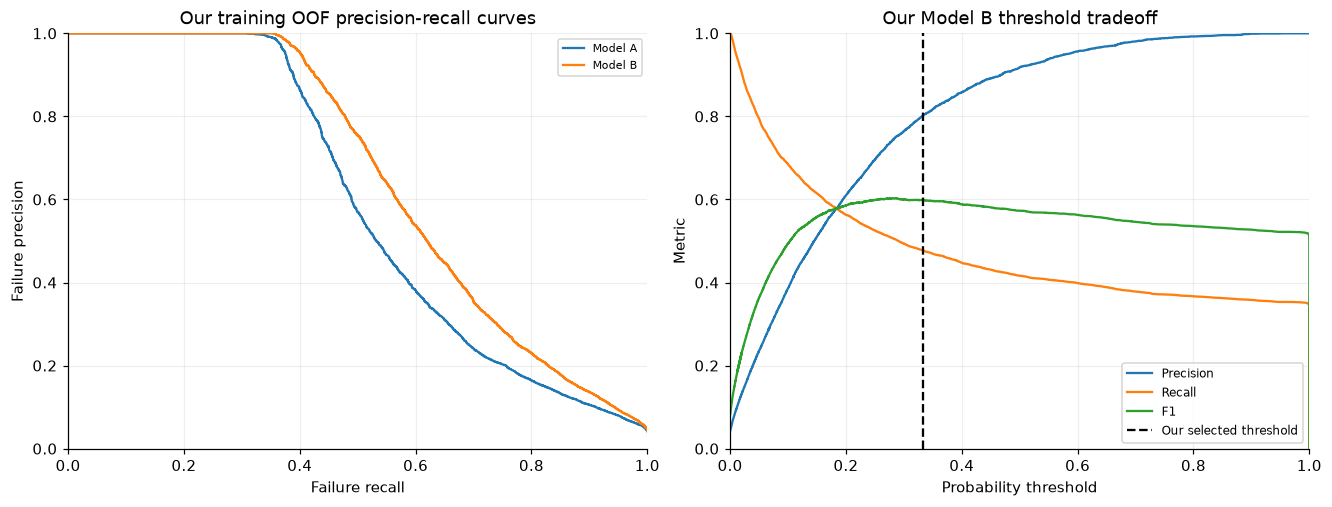

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for name in MODEL_CONFIGS.values():
    pr,re,_=precision_recall_curve(train.loc[eligible,'label'],oof[name][eligible])
    axes[0].plot(re,pr,label=('Model A' if name=='die_only_lgbm' else 'Model B'),linewidth=1.5)
axes[0].set(xlabel='Failure recall',ylabel='Failure precision',title='Our training OOF precision-recall curves',xlim=(0,1),ylim=(0,1))
axes[0].legend(fontsize=7);axes[0].grid(alpha=.2)
pr,re,th=precision_recall_curve(train.loc[eligible,'label'],oof[SELECTED][eligible])
f=2*pr[:-1]*re[:-1]/np.maximum(pr[:-1]+re[:-1],1e-12)
axes[1].plot(th,pr[:-1],label='Precision');axes[1].plot(th,re[:-1],label='Recall');axes[1].plot(th,f,label='F1')
axes[1].axvline(selected_thresholds[DEFAULT_SETTING],color='black',ls='--',label='Our selected threshold')
axes[1].set(xlabel='Probability threshold',ylabel='Metric',title='Our Model B threshold tradeoff',xlim=(0,1),ylim=(0,1))
axes[1].legend(fontsize=8);axes[1].grid(alpha=.2)
fig.savefig(OUTPUT_DIR/'validation_tradeoffs.png',dpi=170);plt.show()

## 6. Our final Model A versus Model B comparison

We fit both models on all training wafers, using inner-fold predictions to train their final classifiers. We evaluate them on exactly the same eligible test dies, with independently training-selected thresholds under the same precision preference. We export both trained models, both probability vectors, and the explicit B-minus-A metric differences.

The provided test set was inspected during earlier development, so these are reused-benchmark results, not fresh independent confirmation. The unlabeled validation file duplicates test inputs in this supplied dataset. We need new external wafers before making production claims.

In [ ]:
test=load(DATA/'test.csv').reset_index(drop=True)
validate_frame(test)
assert not set(train.wafer_id)&set(test.wafer_id), 'Train/test wafer overlap.'
test_matched=extract(DATA/'test.csv',noise)
signal,xt,xv=crossfit(train,test.drop(columns='label'))
xt=extend(xt,train,train_matched);xv=extend(xv,test,test_matched)
test_eligible=test.old_label.to_numpy()==0
trained={};test_predictions={};test_rows=[]
for label,name in [('A','die_only_lgbm'),('B',SELECTED)]:
    cols=candidate_columns(name,xt)
    model=candidate_model(name,train.loc[eligible,'label']).fit(xt.loc[eligible,cols],train.loc[eligible,'label'])
    t0=time.perf_counter();p=model.predict_proba(xv[cols])[:,1];seconds=time.perf_counter()-t0
    trained[label]={'model':model,'columns':cols,'name':name,'thresholds':all_thresholds[name]}
    test_predictions[label]=p
    for setting,t in all_thresholds[name].items():
        test_rows.append({'model':label,'experiment':name,'setting':setting,
          **all_metrics(test.loc[test_eligible,'label'],p[test_eligible],t),
          'second_stage_prediction_seconds':seconds})
test_table=pd.DataFrame(test_rows)
test_table.to_csv(OUTPUT_DIR/'test_results.csv',index=False)
counts={'wafers':int(test.wafer_id.nunique()),'eligible_dies':int(test_eligible.sum()),
        'new_failures':int(test.loc[test_eligible,'label'].sum())}
display(pd.Series(counts).to_frame('test data'))
display(test_table[['model','setting','threshold','fail_f1','auc_pr_average_precision','pr_auc_trapezoidal',
                   'roc_auc','precision','recall','accuracy','balanced_accuracy','brier_score','log_loss']].round(5))
joblib.dump({'signal':signal,'noise':noise,'trained':trained,'feature_columns':PARAM,
             'default_setting':DEFAULT_SETTING,'versions':versions},OUTPUT_DIR/'trained_workflow.joblib')
comparison=test_table[test_table.setting==DEFAULT_SETTING].set_index('model')[
    ['fail_f1','auc_pr_average_precision','roc_auc','precision','recall','accuracy',
     'pass_f1','pass_recall','pass_precision','balanced_accuracy','brier_score','log_loss']]
comparison.loc['B minus A']=comparison.loc['B']-comparison.loc['A']
display(Markdown('### Our required Model A versus Model B results'))
display(comparison.round(5))
comparison.to_csv(OUTPUT_DIR/'model_A_vs_B.csv')
for label,artifact in trained.items():
    assert label=='B' or not any(col.startswith(('block_','matched_')) for col in artifact['columns'])
    joblib.dump({'signal':signal,'noise':noise if label=='B' else None,
                 'model':artifact,'feature_columns':PARAM,'default_setting':DEFAULT_SETTING},
                OUTPUT_DIR/f'model_{label}.joblib')
    export=test[KEYS].copy()
    export['failure_probability']=np.where(test.old_label==1,1,test_predictions[label])
    export['predicted_label']=np.where(test.old_label==1,1,
         test_predictions[label]>=artifact['thresholds'][DEFAULT_SETTING]).astype(int)
    export.to_csv(OUTPUT_DIR/f'test_predictions_{label}.csv',index=False)


,test data
wafers,40
eligible_dies,32598
new_failures,1380


,model,setting,threshold,fail_f1,auc_pr_average_precision,pr_auc_trapezoidal,roc_auc,precision,recall,accuracy,balanced_accuracy,brier_score,log_loss
0,A,f1,0.27246,0.55597,0.59439,0.59459,0.90131,0.78010,0.43188,0.97080,0.71325,0.02408,0.0996
1,A,precision_80,0.28321,0.55446,0.59439,0.59459,0.90131,0.79352,0.42609,0.97101,0.71059,0.02408,0.0996
2,A,precision_90,0.34928,0.54609,0.59439,0.59459,0.90131,0.88474,0.39493,0.97221,0.69633,0.02408,0.0996
3,A,probability_50,0.50000,0.53102,0.59439,0.59459,0.90131,0.96743,0.36594,0.97264,0.68270,0.02408,0.0996
4,B,f1,0.28525,0.59802,0.65285,0.65279,0.93017,0.73751,0.50290,0.97138,0.74749,0.02219,0.0887
5,B,precision_80,0.33250,0.59784,0.65285,0.65279,0.93017,0.79117,0.48043,0.97264,0.73741,0.02219,0.0887
6,B,precision_90,0.46782,0.57998,0.65285,0.65279,0.93017,0.89818,0.42826,0.97374,0.71306,0.02219,0.0887
7,B,probability_50,0.50000,0.57356,0.65285,0.65279,0.93017,0.91297,0.41812,0.97368,0.70818,0.02219,0.0887


### Our required Model A versus Model B results

,fail_f1,auc_pr_average_precision,roc_auc,precision,recall,accuracy,pass_f1,pass_recall,pass_precision,balanced_accuracy,brier_score,log_loss
model,,,,,,,,,,,,
A,0.55446,0.59439,0.90131,0.79352,0.42609,0.97101,0.98502,0.99510,0.97514,0.71059,0.02408,0.0996
B,0.59784,0.65285,0.93017,0.79117,0.48043,0.97264,0.98584,0.99439,0.97742,0.73741,0.02219,0.0887
B minus A,0.04338,0.05846,0.02886,-0.00235,0.05435,0.00163,0.00082,-0.00070,0.00229,0.02682,-0.00188,-0.0109


In [ ]:
# We resample wafers, rather than individual dies, to reflect clustered uncertainty.
selected_p=test_predictions['B'];selected_t=selected_thresholds[DEFAULT_SETTING]
per_wafer=[]
for _,g in test.groupby('wafer_id'):
    ix=g.index[g.old_label==0];y=test.loc[ix,'label'].to_numpy();hat=selected_p[ix]>=selected_t
    per_wafer.append([((y==1)&hat).sum(),((y==0)&hat).sum(),((y==1)&~hat).sum()])
per_wafer=np.array(per_wafer);rng=np.random.default_rng(SEED)
totals=per_wafer[rng.integers(0,len(per_wafer),(2000,len(per_wafer)))].sum(1)
boot_f1=2*totals[:,0]/np.maximum(2*totals[:,0]+totals[:,1]+totals[:,2],1)
f1_ci=np.quantile(boot_f1,[.025,.975]).tolist()
observed=test_table[(test_table.model=='B')&(test_table.setting==DEFAULT_SETTING)].iloc[0]
display(Markdown(f'We observed **F1 {observed.fail_f1:.4f}**, **precision {observed.precision:.4f}**, '
 f'**recall {observed.recall:.4f}**, and **average precision {observed.auc_pr_average_precision:.4f}** '
 f'at our selected operating point. Our wafer-bootstrap 95% interval for F1 is **[{f1_ci[0]:.4f}, {f1_ci[1]:.4f}]**. '
 'This interval does not include model-selection uncertainty or future process drift.'))
results={'selection':selection,'test_counts':counts,'f1_bootstrap_95_interval':f1_ci,
         'test_results':test_table.to_dict('records'),'cv_results':cv_table.to_dict('records'),
         'versions':versions,'benchmark_status':'reused benchmark; not a fresh independent test'}
(OUTPUT_DIR/'results.json').write_text(json.dumps(results,indent=2))

We observed **F1 0.5978**, **precision 0.7912**, **recall 0.4804**, and **average precision 0.6529** at our selected operating point. Our wafer-bootstrap 95% interval for F1 is **[0.5686, 0.6194]**. This interval does not include model-selection uncertainty or future process drift.

15262

## 7. Our Model A and Model B explanations

We inspect the confusion matrix, precision-recall curves, and calibration. We also show spatial predictions and the strongest scanned block location for a candidate flagged die. Those locations describe model evidence; they are not causal diagnoses.

For Model B's logistic fusion we can exactly decompose its log odds into scaled-feature contributions. For Model A, we use exact TreeSHAP contributions. We export a separate explanation file for each model. These explain the final fusion inputs. We separately report the strongest original measurement contributions to our first-stage projection and the removed wafer drift; we do not mislabel these as exact end-to-end attributions.

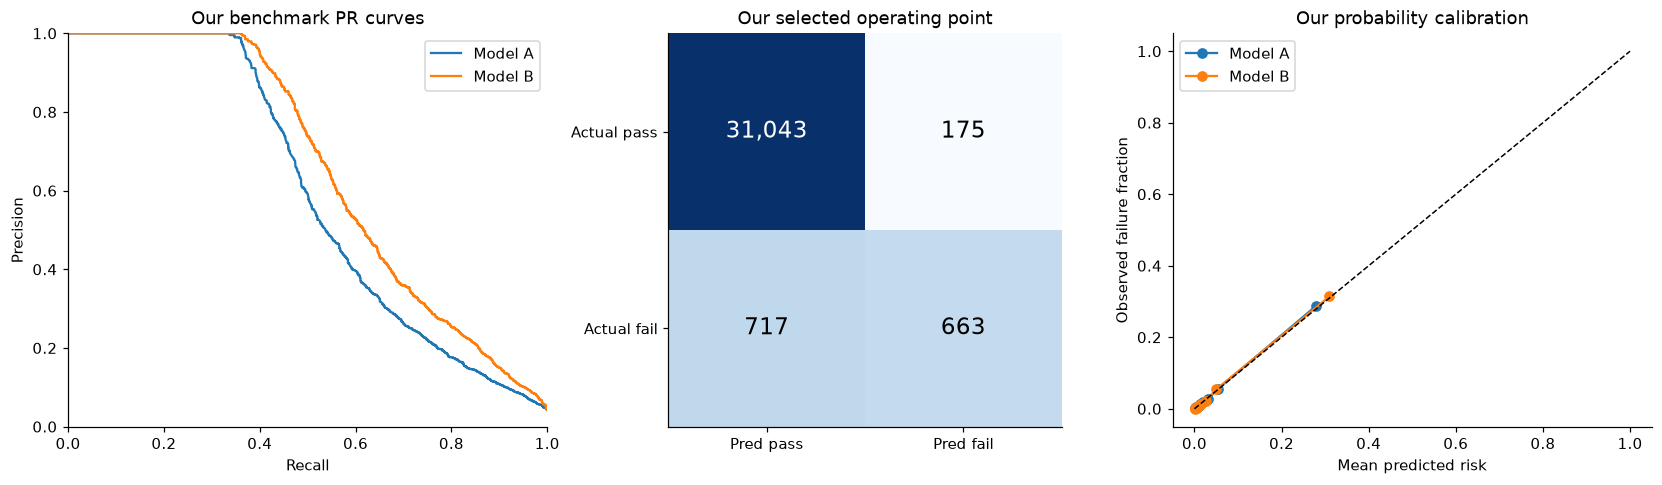

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(15,4.3),layout='constrained')
for label,p in test_predictions.items():
    pr,re,_=precision_recall_curve(test.loc[test_eligible,'label'],p[test_eligible])
    axes[0].plot(re,pr,label=f'Model {label}')
axes[0].set(xlabel='Recall',ylabel='Precision',title='Our benchmark PR curves',xlim=(0,1),ylim=(0,1));axes[0].legend()
cm=confusion_matrix(test.loc[test_eligible,'label'],selected_p[test_eligible]>=selected_t)
axes[1].imshow(np.log1p(cm),cmap='Blues')
for i in range(2):
    for j in range(2):axes[1].text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if i==j==0 else 'black',fontsize=15)
axes[1].set(xticks=[0,1],yticks=[0,1],xticklabels=['Pred pass','Pred fail'],yticklabels=['Actual pass','Actual fail'],title='Our selected operating point')
from sklearn.calibration import calibration_curve
for label,p in test_predictions.items():
    frac,mean=calibration_curve(test.loc[test_eligible,'label'],p[test_eligible],n_bins=10,strategy='quantile')
    axes[2].plot(mean,frac,'o-',label=f'Model {label}')
axes[2].plot([0,1],[0,1],'k--',lw=1);axes[2].set(xlabel='Mean predicted risk',ylabel='Observed failure fraction',title='Our probability calibration');axes[2].legend()
fig.savefig(OUTPUT_DIR/'benchmark_checks.png',dpi=170);plt.show()

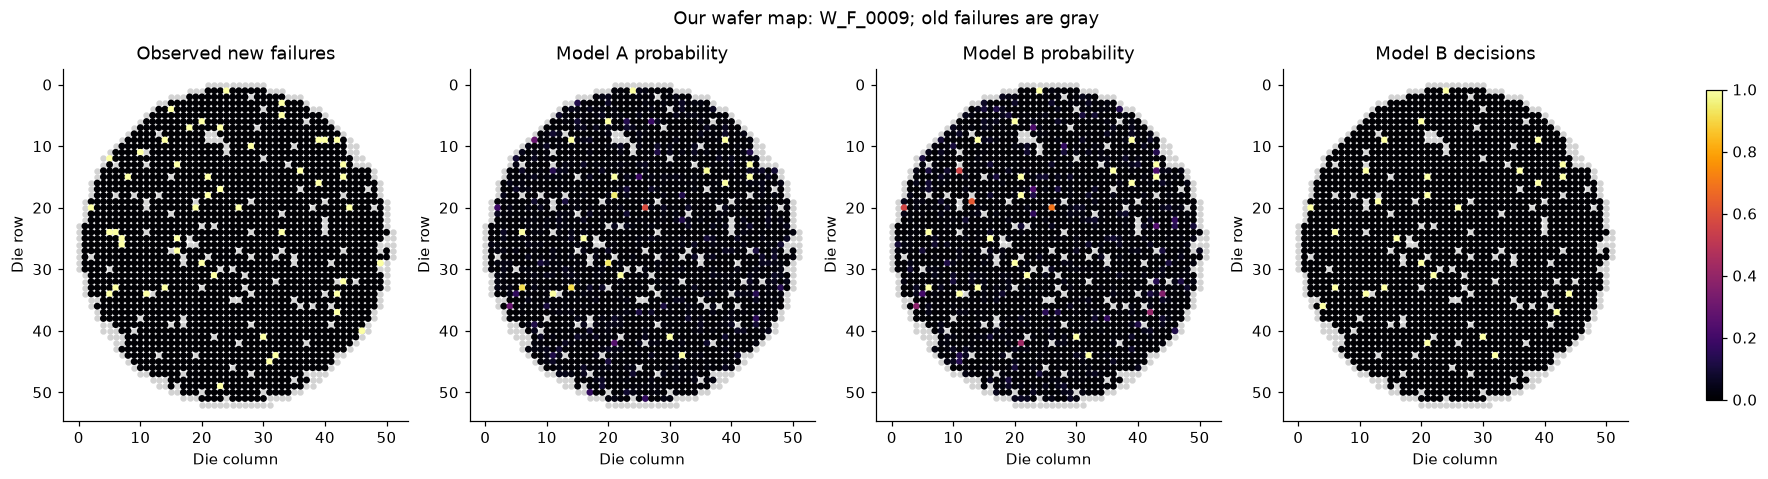

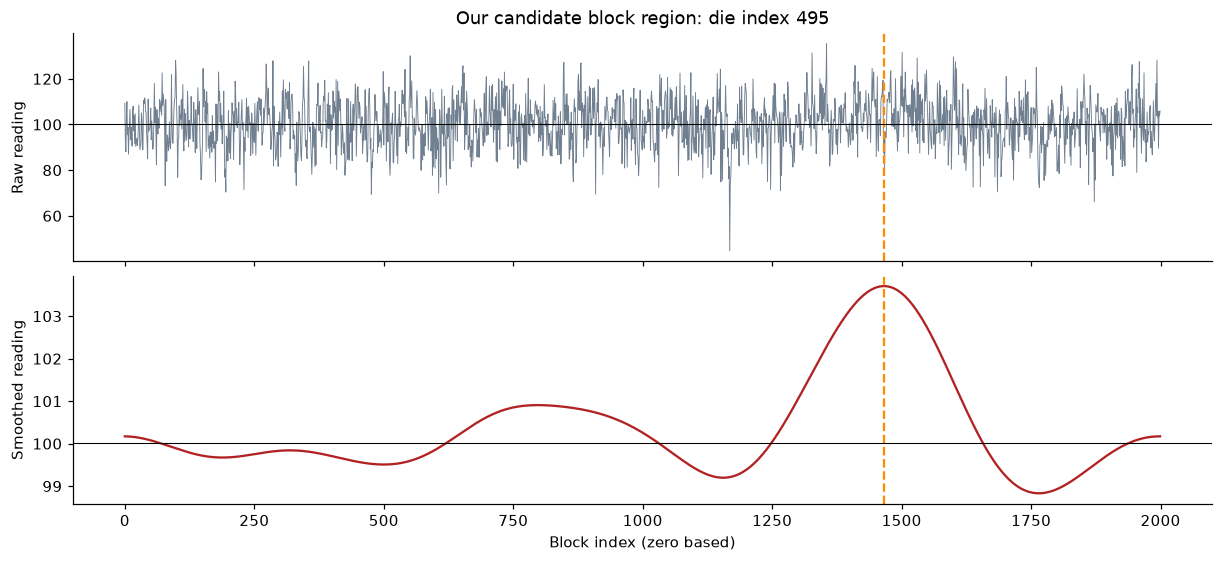

In [ ]:
wafer=test.loc[test_eligible].wafer_id.value_counts().index[0]
whole=test.wafer_id==wafer;pick=whole&test_eligible
fig,axes=plt.subplots(1,4,figsize=(16,4.3),layout='constrained')
for ax,values,title in zip(axes,[test.label.to_numpy(),test_predictions['A'],selected_p,selected_p>=selected_t],
                          ['Observed new failures','Model A probability','Model B probability','Model B decisions']):
    ax.scatter(test.loc[whole,'die_col'],test.loc[whole,'die_row'],s=10,color='lightgray')
    im=ax.scatter(test.loc[pick,'die_col'],test.loc[pick,'die_row'],c=values[pick],s=12,cmap='inferno',vmin=0,vmax=1)
    ax.set(title=title,xlabel='Die column',ylabel='Die row',aspect='equal');ax.invert_yaxis()
fig.colorbar(im,ax=axes,shrink=.75);fig.suptitle(f'Our wafer map: {wafer}; old failures are gray')
fig.savefig(OUTPUT_DIR/'wafer_map.png',dpi=170);plt.show()

candidate=np.flatnonzero(test_eligible&(selected_p>=selected_t)&(np.arange(len(test))<2000))
if not len(candidate):candidate=np.flatnonzero(test_eligible)[:1]
ix=int(candidate[np.argmax(test_matched.loc[candidate,'matched_llr_100'].to_numpy())])
reading=pd.read_csv(DATA/'test.csv',nrows=ix+1,usecols=['block_readings']).iloc[ix,0]
reading=np.fromstring(reading,sep=' ');center=int(test_matched.loc[ix,'matched_center_100'])
fig,axes=plt.subplots(2,1,figsize=(11,5),sharex=True,layout='constrained')
axes[0].plot(reading,lw=.6,color='slategray');axes[0].set(ylabel='Raw reading',title=f'Our candidate block region: die index {ix}')
axes[1].plot(gaussian_filter1d(reading,100,mode='wrap'),color='firebrick');axes[1].set(xlabel='Block index (zero based)',ylabel='Smoothed reading')
for ax in axes:ax.axvline(center,ls='--',color='darkorange');ax.axhline(noise['mean'],color='black',lw=.7)
fig.savefig(OUTPUT_DIR/'block_region.png',dpi=170);plt.show()

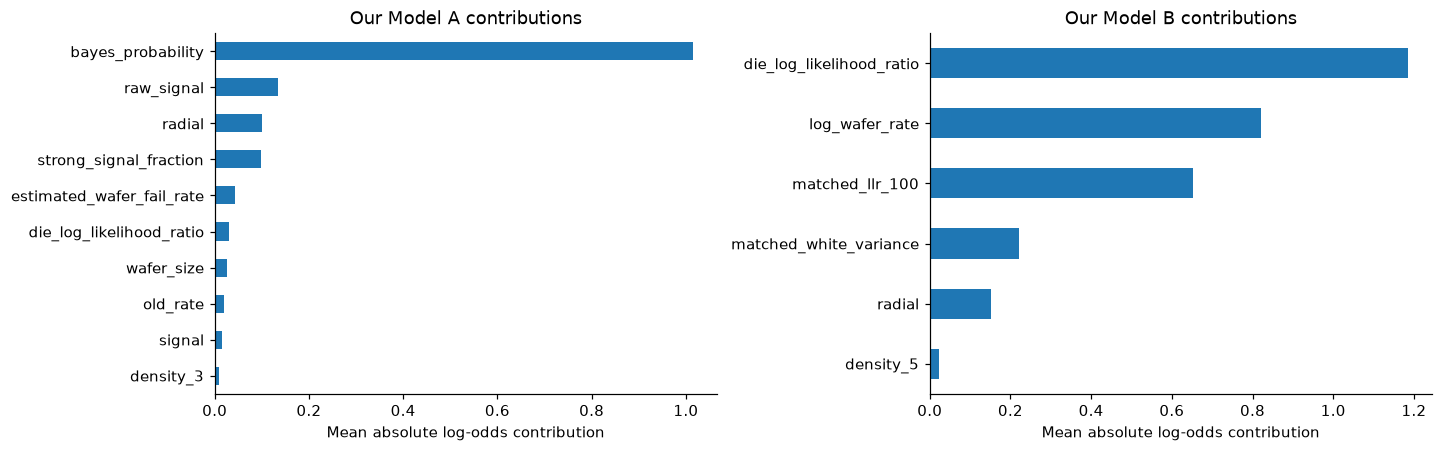

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for panel,(label,final) in enumerate(trained.items()):
    xm=xv[final['columns']];model=final['model']
    if label=='B':
        contributions=model[0].transform(xm)*model[-1].coef_[0]
        base=np.full(len(xm),model[-1].intercept_[0])
    else:
        values=model.booster_.predict(xm,pred_contrib=True)
        contributions,base=values[:,:-1],values[:,-1]
    assert np.allclose(expit(contributions.sum(1)+base),test_predictions[label],atol=1e-5)
    explanations=test[KEYS].copy()
    for j,col in enumerate(final['columns']):explanations['contribution_'+col]=contributions[:,j]
    explanations['base_log_odds']=base
    explanations['failure_probability']=test_predictions[label]
    if label=='B':explanations['peak_block_index']=test_matched.matched_center_100
    explanations.to_csv(OUTPUT_DIR/f'explanations_{label}.csv',index=False)
    importance=pd.Series(np.abs(contributions[test_eligible]).mean(0),index=final['columns']).sort_values()
    importance.tail(10).plot.barh(ax=axes[panel],title=f'Our Model {label} contributions')
    axes[panel].set_xlabel('Mean absolute log-odds contribution')
fig.savefig(OUTPUT_DIR/'model_explanations.png',dpi=170);plt.show()
raw_contributions=((test[PARAM].to_numpy()-signal.mean)/signal.scale)*signal.direction
top=np.argsort(raw_contributions,axis=1)[:,-3:][:,::-1]
drivers=test[KEYS].copy()
for k in range(3):
    drivers[f'feature_{k+1}']=np.asarray(PARAM)[top[:,k]]
    drivers[f'projection_contribution_{k+1}']=raw_contributions[np.arange(len(test)),top[:,k]]
drivers['removed_process_drift']=xv.raw_signal-xv.signal
drivers.to_csv(OUTPUT_DIR/'parametric_drivers.csv',index=False)

## 8. Our separate Model A and Model B submissions

We generate `submission_A.csv` and `submission_B.csv`, each with the required columns `wafer_id, die_row, die_col, predicted_label`. Each has a companion probability file. We use each model's own validation-selected threshold.

Model A's predictor accepts a CSV without `block_readings`; it neither parses nor scans block data. Model B requires block readings. We explicitly discard any supplied post-test target column. Our checks verify that removing all block-derived information leaves Model A's predictions unchanged, alongside target independence and row alignment.

In [ ]:
def predict_complete_wafers(path, model_label='B', setting=DEFAULT_SETTING):
    assert model_label in trained
    if model_label=='A':
        raw=pd.read_csv(path,usecols=lambda col:col!='block_readings' and not col.startswith('block_'))
        raw=raw.astype({col:np.float32 for col in PARAM}).reset_index(drop=True)
    else:
        raw=load(Path(path)).reset_index(drop=True)
    raw=raw.drop(columns='label',errors='ignore')
    validate_frame(raw,labeled=False)
    features=signal.features(raw)
    if model_label=='B':features=extend(features,raw,extract(Path(path),noise))
    artifact=trained[model_label]
    probability=artifact['model'].predict_proba(features[artifact['columns']])[:,1]
    t=artifact['thresholds'][setting]
    output=raw[KEYS].copy()
    output['predicted_label']=np.where(raw.old_label==1,1,probability>=t).astype(int)
    output.to_csv(OUTPUT_DIR/f'submission_{model_label}.csv',index=False)
    detail=output.copy();detail['failure_probability']=np.where(raw.old_label==1,1,probability)
    detail.to_csv(OUTPUT_DIR/f'submission_{model_label}_probabilities.csv',index=False)
    assert output[KEYS].equals(raw[KEYS])
    assert output.loc[raw.old_label==1,'predicted_label'].eq(1).all()
    return output

submissions={}
for label in ['A','B']:
    t0=time.perf_counter();submissions[label]=predict_complete_wafers(DATA/'validation.csv',label)
    print(f'Model {label}: {len(submissions[label]):,} predictions, {time.perf_counter()-t0:.2f} seconds.')
sample=test[test.wafer_id==test.wafer_id.iloc[0]].reset_index(drop=True)
reference=signal.features(sample.drop(columns='label'))
altered=sample.copy();altered['label']=1-altered.label
assert np.allclose(reference,signal.features(altered))
assert np.allclose(reference,signal.features(sample.iloc[::-1].reset_index(drop=True)).iloc[::-1])
block_free=sample.drop(columns=[col for col in sample if col.startswith('block_')]+['label'])
a=trained['A']
assert np.allclose(a['model'].predict_proba(reference[a['columns']]),
                   a['model'].predict_proba(signal.features(block_free)[a['columns']]))
assert len(trained)==2 and set(trained)=={'A','B'}
print('Both model contracts passed: Model A is block-independent; targets and row order do not change context; both submissions are aligned.')
display(submissions['A'].head());display(submissions['B'].head())


Model A: 39,351 predictions, 16.91 seconds.


Model B: 39,351 predictions, 1.50 seconds.


Both model contracts passed: Model A is block-independent; targets and row order do not change context; both submissions are aligned.


,wafer_id,die_row,die_col,predicted_label
0,W_F_0014,0,17,1
1,W_F_0014,0,18,0
2,W_F_0014,0,19,1
3,W_F_0014,0,20,1
4,W_F_0014,0,21,0


,wafer_id,die_row,die_col,predicted_label
0,W_F_0014,0,17,1
1,W_F_0014,0,18,0
2,W_F_0014,0,19,1
3,W_F_0014,0,20,1
4,W_F_0014,0,21,0


## 9. Our conclusion: the required two-model solution

We deliver **Model A: die-level measurements plus spatial context**, and **Model B: the same source information plus block-level evidence**. We compare their results, probabilities, explanations, and separate submission files on a shared wafer-level evaluation.

The B-minus-A table quantifies the observed pipeline difference. We report decreases as well as increases, and do not claim every metric must improve. Because the final classifiers differ, we do not attribute the entire change to block readings alone.

We choose thresholds from training predictions and show the precision-recall tradeoff. A different manufacturing cost balance could justify a different threshold. New production wafers are needed to confirm generalization.

Our deliverables generated by this notebook are `model_A.joblib`, `model_B.joblib`, `model_A_vs_B.csv`, `explanations_A.csv`, `explanations_B.csv`, shared measurement drivers, spatial/block visualizations, `submission_A.csv`, and `submission_B.csv`. To load saved models later, first execute our class/function definitions and load only trusted files. No external Python script or precomputed cache is required.

In [ ]:
display(Markdown('### Our final deliverables: Model A and Model B'))
display(comparison.round(5))
for label in ['A','B']:
    print(f"Model {label}: threshold {trained[label]['thresholds'][DEFAULT_SETTING]:.6f}; submission_{label}.csv")
print('Our output directory:', OUTPUT_DIR)
print('Elapsed notebook workflow seconds:',round(time.perf_counter()-started,2))


### Our final deliverables: Model A and Model B

,fail_f1,auc_pr_average_precision,roc_auc,precision,recall,accuracy,pass_f1,pass_recall,pass_precision,balanced_accuracy,brier_score,log_loss
model,,,,,,,,,,,,
A,0.55446,0.59439,0.90131,0.79352,0.42609,0.97101,0.98502,0.99510,0.97514,0.71059,0.02408,0.0996
B,0.59784,0.65285,0.93017,0.79117,0.48043,0.97264,0.98584,0.99439,0.97742,0.73741,0.02219,0.0887
B minus A,0.04338,0.05846,0.02886,-0.00235,0.05435,0.00163,0.00082,-0.00070,0.00229,0.02682,-0.00188,-0.0109


Model A: threshold 0.283211; submission_A.csv
Model B: threshold 0.332501; submission_B.csv
Our output directory: C:\Users\adila\OneDrive\Desktop\sandisk2\die_yield_outputs
Elapsed notebook workflow seconds: 190.46
